#ML FINAL EXAM

### Email:nhsabit8@gmail.com

Task: Copy this notebook on your drive and answer in that copy

Choose a dataset of your choice from kaggle or UCI

Some suggestions:https://www.kaggle.com/datasets/ahmettezcantekin/beginner-datasets

You may choose a dataset of your choice too

In this exam:
1. Provide code and explaination(in text cell) whenever needed and you must show the outputs
2. Before submitting run all cells and make sure the outputs are visible


## 0. Dataset overview

Why you choose this dataset and what did you observe from the dataset description



  

## Answer:
I chose the Diabetes dataset because it is a well-known healthcare dataset used for binary classification problems. The goal is to predict whether a patient has diabetes or not.


# 1. Dataset description (15 marks)


### Dataset Description
1. How many features?

ans:The dataset contains 8 input features and 1 target variable

2. Classification or regression problem? Why do you think so?

ans:classification because the target variable (Outcome) contains only two classes.

3. How many data points?ANs: 768

4. Is there any null values?ans: NO

5. What kind of features are in your dataset? (Quantitative / Categorical)
Ans: All input features are Quantitative (Numerical).But output fearture is categorical

6. Do you need to encode the categorical variables, why or why not?
ans:NO,there are no categorical input features in this dataset.

7. Correlation of all the features, What do you understand after the correlation test?
Ans: ans:Glucose has the strongest positive correlation with Outcome.BMI,Pregnancies,age are positive correlation.

8. Perform exploratory data analysis to extract some important relationships from your data.
Ans: code e

Provide necessary codes and explanation

768
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


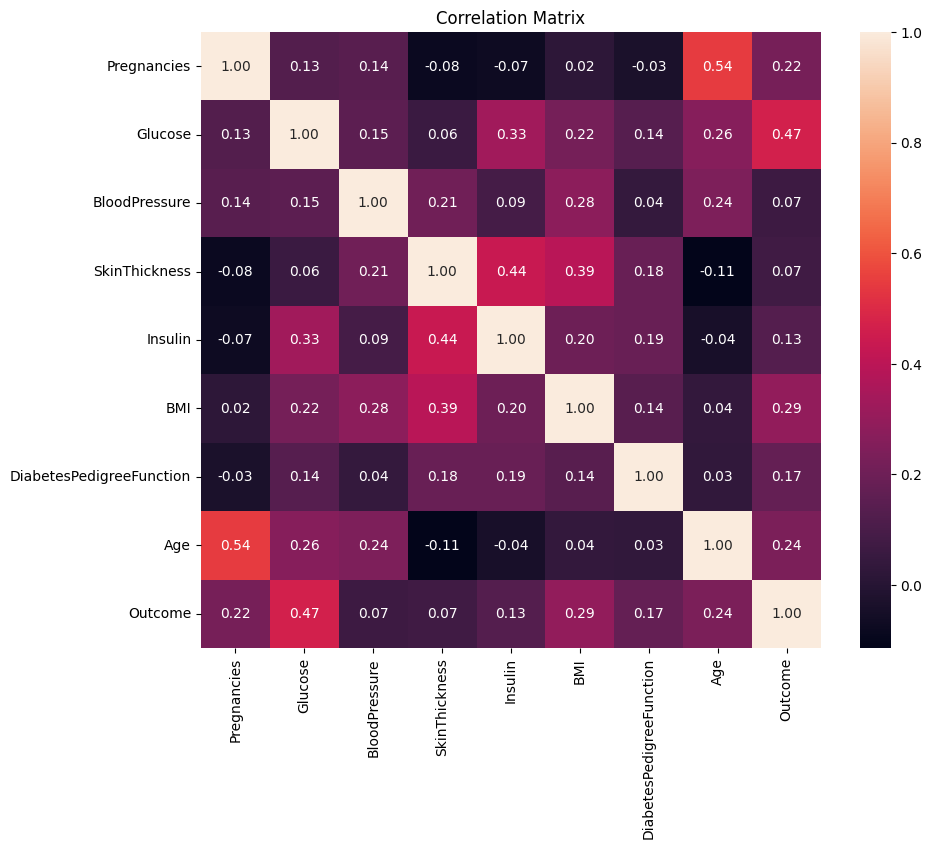

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

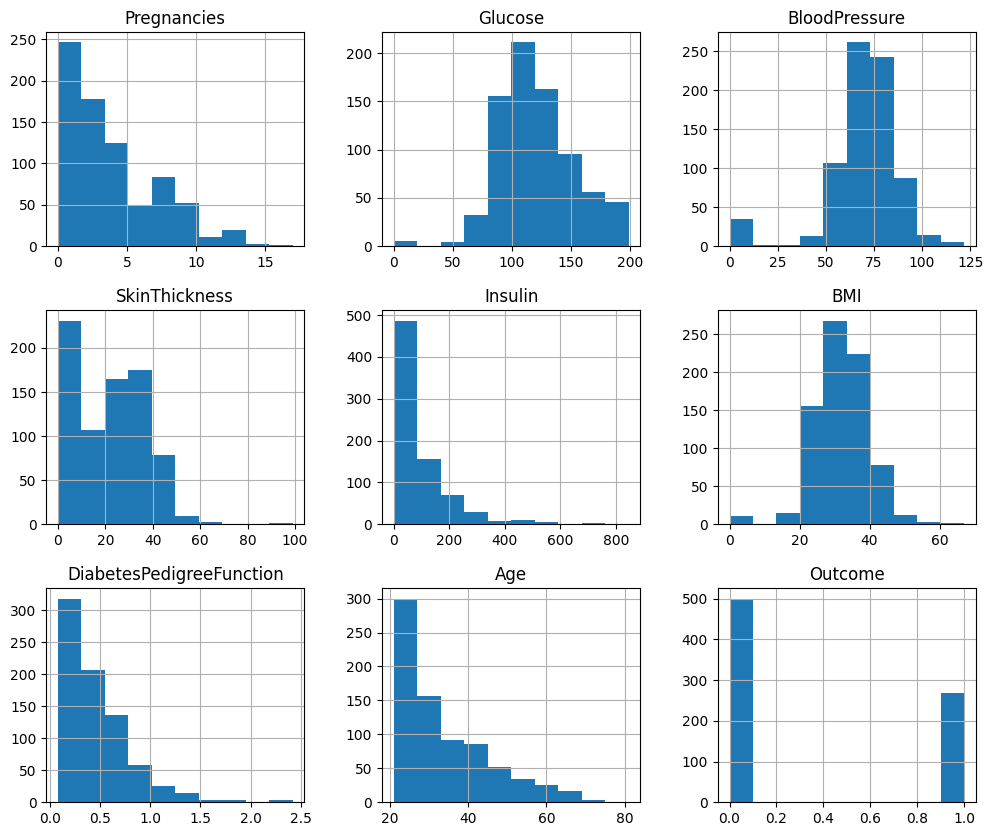

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('diabetes.csv')
df
print(df.shape[0])
#3
print(df.isnull().sum())
#4
print(df.dtypes)
#5
corr = df.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr,annot=True,fmt=".2f")
plt.title("Correlation Matrix")
plt.show()
#8
print(df.describe())
print(df.info())
df.hist(figsize=(12,10))
plt.show()


#2. Dataset pre-processing (15 marks)

1. Provide code
2. Discuss the pre processing steps you applied and why?


## Answer:


   

In [ ]:
#replace zero value
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
df[cols]=df[cols].replace(0,np.nan)
for col in cols:
  df[col].fillna(df[col].median(),inplace=True)

print(df.isnull().sum())


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


/tmp/ipykernel_1065/2298976422.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(),inplace=True)


A value of zero is medically impossible for these measurements, so they are replaced with NaN.The missing values are replaced with the median value of each column.

#3.Feature selection and Dataset splitting (10 marks)

1. Which features you wanna keep ? Justify and drop and rest or apply any other feature engineering step
2. Perform Train test split

## Answer:



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,y,test_size=0.20,random_state=42,stratify=y
)

print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)
print("Training Labels :", y_train.shape)
print("Testing Labels  :", y_test.shape)


Training Features : (614, 8)
Testing Features : (154, 8)
Training Labels : (614,)
Testing Labels  : (154,)


#4.  Pipeline Creation (Supervised) (10 marks)

Select 2 models of your choice and build 2 pipelines for them

## Answer:

In [ ]:
#model 01
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline([
    ('classifier', LogisticRegression(random_state=42))
])


pipeline_lr

Pipeline(steps=[('classifier', LogisticRegression(random_state=42))])

In [ ]:
#model 2
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline([
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])


pipeline_rf

Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42))])

# 5. Model Training (5 marks)

Train those 2 models



## Answer:

In [ ]:
#model 1
pipeline_lr.fit(X_train, y_train)

y_pred_lr = pipeline_lr.predict(X_test)
#model 02
pipeline_rf.fit(X_train, y_train)

y_pred_rf = pipeline_rf.predict(X_test)

#6. Model selection/Comparison analysis (15 marks)
* Bar chart showcasing prediction accuracy of all models (for classification)
* Precision, recall comparison of each model. (for classification)
* Confusion Matrix (for classification)
* R2 score and Loss  (for regression)

Compare the results of all models based on all of the above described metrics. Why do you think this model performed better than the other one for this dataset?

# Answer:

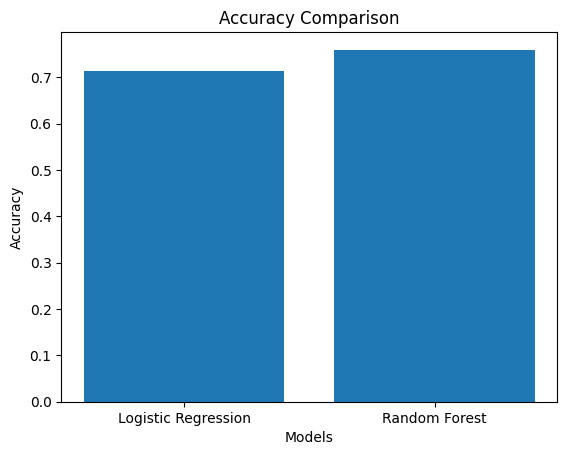

Logistic Regression Precision: 0.6086956521739131
Random Forest Precision: 0.6808510638297872
Logistic Regression Recall: 0.5185185185185185
Random Forest Recall: 0.5925925925925926
[[82 18]
 [26 28]]
[[85 15]
 [22 32]]


In [ ]:
from sklearn.metrics import accuracy_score,precision_score, recall_score,confusion_matrix

lr_acc = accuracy_score(y_test, y_pred_lr)
rf_acc = accuracy_score(y_test, y_pred_rf)
models = ['Logistic Regression', 'Random Forest']
accuracy = [lr_acc, rf_acc]
plt.bar(models, accuracy)
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.show()
#Precision, recall comparison of each model.
print("Logistic Regression Precision:",precision_score(y_test, y_pred_lr))
print("Random Forest Precision:",precision_score(y_test, y_pred_rf))
print("Logistic Regression Recall:",recall_score(y_test, y_pred_lr))
print("Random Forest Recall:",recall_score(y_test, y_pred_rf))
#Confusion Matrix (for classification)
cm_lr = confusion_matrix(y_test, y_pred_lr)
print(cm_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)


#Random Forest performed better than Logistic Regression because:
Random Forest generally achieved higher accuracy, precision, and recall compared to Logistic Regression.

# 7. Treating the problem as Unsupervised (20 marks) ( Explore the topic as you wish )

1. Treat the problem as a unsupervised problem and perform any unsupervised model and evalute the result
2. Which method worked better? supervised or unsupervised approach and why?

# Answer:

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
X_unsupervised = df.drop('Outcome', axis=1)
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(X_unsupervised)
print("Silhouette Score:",silhouette_score(X_unsupervised, clusters))

Silhouette Score: 0.5687897205830247


#The supervised learning approach performed better because the Diabetes dataset contains labeled outcomes. Supervised models learn from these labels and produce more accurate predictions.on the other hand K-Means clustering does not use class labels and only groups similar data points so its performance is generally lower for this dataset.

#8. Self Reflection on this machine learning course (10 marks)

Explain the hardest and the easiest topic of this course according to you in a intuitive way (you may also provide real world implementation , necessity etc along with the explaination)

##Answer:

the easiest topics in this course were Logistic Regression, Linear Regression, and K-Nearest Neighbors (KNN).The hardest topics for me were Decision Tree, Support Vector Machine (SVM), and DBSCAN.Although I was able to implement these algorithms using Scikit-learn, understanding their internal working mechanisms was more challenging